AOI features found: 1
    year    C_mean
0   2008  0.061483
1   2009  0.088642
2   2010  0.088495
3   2011  0.051281
4   2012  0.047500
5   2013  0.050576
6   2014  0.062711
7   2015  0.076086
8   2016  0.035829
9   2017  0.061332
10  2018  0.055723
11  2019  0.060672
12  2020  0.064308
13  2021  0.057187
14  2022  0.040035
Figure saved: C:\Users\Кирилл\Portfolio\project-rusle-c-factor\figures\c_factor_timeseries.png


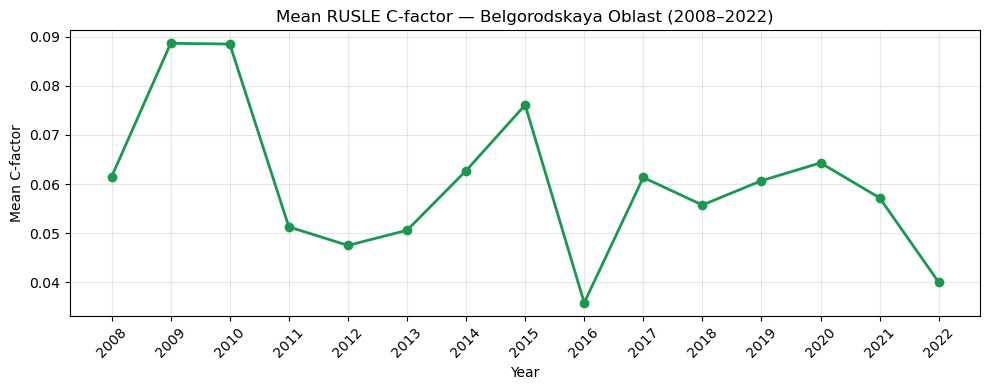

 year   C_mean
 2008 0.061483
 2009 0.088642
 2010 0.088495
 2011 0.051281
 2012 0.047500
 2013 0.050576
 2014 0.062711
 2015 0.076086
 2016 0.035829
 2017 0.061332
 2018 0.055723
 2019 0.060672
 2020 0.064308
 2021 0.057187
 2022 0.040035

Descriptive statistics:
count    15.000000
mean      0.060124
std       0.015239
min       0.035829
25%       0.050928
50%       0.060672
75%       0.063509
max       0.088642
Name: C_mean, dtype: float64
Saved: C:\Users\Кирилл\Portfolio\project-rusle-c-factor\data\C_factor_mean_Belgorodskaya_Oblast.csv
Started export task: C_factor_Belgorodskaya_Oblast_2008
Started export task: C_factor_Belgorodskaya_Oblast_2009
Started export task: C_factor_Belgorodskaya_Oblast_2010
Started export task: C_factor_Belgorodskaya_Oblast_2011
Started export task: C_factor_Belgorodskaya_Oblast_2012
Started export task: C_factor_Belgorodskaya_Oblast_2013
Started export task: C_factor_Belgorodskaya_Oblast_2014
Started export task: C_factor_Belgorodskaya_Oblast_2015
Starte

In [12]:
# ============================================================================
# Расчёт C-фактора RUSLE для Белгородской области, 2008–2022
# ----------------------------------------------------------------------------
# Метод:    C = exp(-a * NDVI / (b - NDVI)), a = 2, b = 1
# Источник: Van der Knijff et al. (2000), применён к MODIS NDVI
# Вход:     MODIS/061/MOD13Q1 NDVI (16-дневный, 250 м)
# Сезон:    май–сентябрь (вегетационный период)
# Выход:    Годовые карты C-фактора + CSV со статистикой + экспорт в Drive
# Автор:    Бабушкин Кирилл Сергеевич (Python-порт)
# Лицензия: MIT
# ОГРАНИЧЕНИЯ:
#   Коэффициенты a=2, b=1 взяты из Van der Knijff et al. (2000) как есть,
#   без региональной калибровки.
#   Литература (Буряк и др., 2023) показывает, что для Белгородской области
#   эта формула систематически занижает C-фактор примерно в 2.16 раза.
#   Региональная калибровка вне рамок данного пайплайна.
# ============================================================================

import re
import geemap
import sys
import ee
from pathlib import Path

sys.path.append(str(Path.cwd()))

from utils import save_fig, ee_stats_to_df, FIGURES_DIR

ee.Initialize()

# ----------------------------------------------------------------------------
# 1. КОНФИГУРАЦИЯ
# ----------------------------------------------------------------------------
CONFIG = {
    'aoiName':      'Belgorodskaya Oblast',
    'startYear':    2008,
    'endYear':      2022,
    'scale':        250,
    'a':            2,             # коэффициент RUSLE
    'b':            1,             # коэффициент RUSLE
    'seasonStart':  5,             # май
    'seasonLength': 5,             # 5 месяцев → май–сентябрь
    'ndviMaxClamp': 0.99,          # защита от деления на ~0 при NDVI → 1
    'crs':          'EPSG:32637',  # UTM зона 37N
    'exportFolder': 'GEE_rusle_c_factor'
}


# ----------------------------------------------------------------------------
# 2. ГРАНИЦЫ ИССЛЕДУЕМОЙ ТЕРРИТОРИИ
# ----------------------------------------------------------------------------
aoiFC = (ee.FeatureCollection('FAO/GAUL_SIMPLIFIED_500m/2015/level1')
         .filter(ee.Filter.eq('ADM1_NAME', CONFIG['aoiName'])))

print('AOI features found:', aoiFC.size().getInfo())   # должно быть 1

AOI   = aoiFC.geometry()
YEARS = ee.List.sequence(CONFIG['startYear'], CONFIG['endYear'])


Map = geemap.Map()
Map.centerObject(AOI, 8)


# ----------------------------------------------------------------------------
# 3. СРЕДНИЙ NDVI ЗА СЕЗОН (май–сентябрь, с маской QA)
# ----------------------------------------------------------------------------
# SummaryQA: -1 = заполнение, 0 = хорошо, 1 = приемлемо, 2 = снег/лёд, 3 = облака
def maskQA(img):
    qa = img.select('SummaryQA')
    return img.updateMask(qa.gte(0)).updateMask(qa.lte(1))


def annualNdvi(year):
    year  = ee.Number(year)
    start = ee.Date.fromYMD(year, CONFIG['seasonStart'], 1)
    end   = start.advance(CONFIG['seasonLength'], 'month')

    return (ee.ImageCollection('MODIS/061/MOD13Q1')
            .select(['NDVI', 'SummaryQA'])
            .filterDate(start, end)
            .map(maskQA)
            .select('NDVI')                # убираем канал QA после маски
            .mean()
            .multiply(0.0001)              # масштабный коэффициент MODIS
            .clip(AOI)
            .rename('NDVI')
            .set('year', year)
            .set('system:time_start', start.millis()))


ndviSeries = ee.ImageCollection(YEARS.map(annualNdvi))


# ----------------------------------------------------------------------------
# 4. C-ФАКТОР RUSLE
# ----------------------------------------------------------------------------
def toCfactor(img):
    # Ограничиваем NDVI физическим диапазоном: отрицательные значения
    # приходят от воды и остаточного снега
    ndvi  = img.select('NDVI').clamp(0, CONFIG['ndviMaxClamp'])
    denom = ee.Image(CONFIG['b']).subtract(ndvi)

    c = (ndvi.divide(denom)
         .multiply(-CONFIG['a'])
         .exp()
         .min(1)     # C = 1 соответствует чистой почве (пар)
         .max(0)     # нижняя граница
         .rename('C'))

    return c.copyProperties(img, ['year', 'system:time_start'])


cSeries = ndviSeries.map(toCfactor)


# ----------------------------------------------------------------------------
# 5. ВИЗУАЛИЗАЦИЯ
# ----------------------------------------------------------------------------
cVis = {
    'min': 0,
    'max': 1,
    'palette': ['1a9850', 'ffffbf', 'd73027']
}

Map.addLayer(cSeries.first(),
             cVis,
             'C-factor ' + str(CONFIG['startYear']))

Map.addLayer(cSeries.filter(ee.Filter.eq('year', CONFIG['endYear'])).first(),
             cVis,
             'C-factor ' + str(CONFIG['endYear']),
             False)

Map


# ----------------------------------------------------------------------------
# 6. СТАТИСТИКА СРЕДНЕГО C-ФАКТОРА ПО ОБЛАСТИ
# ----------------------------------------------------------------------------
def calc_stats(img):
    img = ee.Image(img).rename('C')

    stats = img.reduceRegion(
        reducer   = ee.Reducer.mean(),
        geometry  = AOI,
        scale     = CONFIG['scale'],
        maxPixels = 1e13,
        tileScale = 4
    )

    return ee.Feature(None, {
        'year':   img.get('year'),
        'C_mean': stats.get('C')
    })


cStats = ee.FeatureCollection(cSeries.map(calc_stats)).sort('year')


# ----------------------------------------------------------------------------
# 7. ГРАФИК — ВРЕМЕННОЙ РЯД СРЕДНЕГО C-ФАКТОРА
# ----------------------------------------------------------------------------
import matplotlib.pyplot as plt

df = ee_stats_to_df(cStats)          # функция из utils
print(df)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(df['year'], df['C_mean'],
        marker='o', linewidth=2, color='#1a9850')

ax.set_xlabel('Год')
ax.set_ylabel('Средний C-фактор')
ax.set_title(
    f"Средний C-фактор RUSLE — {CONFIG['aoiName']} "
    f"({CONFIG['startYear']}–{CONFIG['endYear']})"
)
ax.set_xticks(df['year'])
ax.tick_params(axis='x', rotation=45)
ax.grid(alpha=0.3)

plt.tight_layout()

save_fig(fig, 'C_factor_timeseries.png')
plt.show()


# ----------------------------------------------------------------------------
# 8. ТАБЛИЦА — СРЕДНИЕ ЗНАЧЕНИЯ ПО ГОДАМ + ЛОКАЛЬНЫЙ CSV
# ----------------------------------------------------------------------------
print(df.to_string(index=False, float_format=lambda x: f'{x:.6f}'))

print('\nОписательная статистика:')
print(df['C_mean'].describe())

# Папка data рядом с ноутбуком
data_dir = Path.cwd().parent / 'data'      # если ноутбук в python/
data_dir.mkdir(parents=True, exist_ok=True)

# Сохраняем DataFrame в CSV
csv_path = data_dir / 'C_factor_mean_Belgorodskaya_Oblast.csv'
df.to_csv(csv_path, index=False)

print(f'Saved: {csv_path.resolve()}')


# ----------------------------------------------------------------------------
# 9. ЭКСПОРТ — РАСТРЫ (15 годовых карт C-фактора)
# ----------------------------------------------------------------------------
safe_name = re.sub(r'\s+', '_', CONFIG['aoiName'])

for year in range(CONFIG['startYear'], CONFIG['endYear'] + 1):
    img = cSeries.filter(ee.Filter.eq('year', year)).first()

    task = ee.batch.Export.image.toDrive(
        image       = img.toFloat(),
        description = f'C_factor_{safe_name}_{year}',
        folder      = CONFIG['exportFolder'],
        region      = AOI,
        scale       = CONFIG['scale'],
        maxPixels   = 1e13,
        crs         = CONFIG['crs']
    )
    task.start()
    print(f'Started export task: C_factor_{safe_name}_{year}')


# ----------------------------------------------------------------------------
# 10. ЭКСПОРТ — CSV СО СРЕДНИМ C-ФАКТОРОМ (в Google Drive)
# ----------------------------------------------------------------------------
task = ee.batch.Export.table.toDrive(
    collection  = cStats,
    description = f'C_factor_mean_{safe_name}',
    folder      = CONFIG['exportFolder'],
    fileFormat  = 'CSV'
)
task.start()
print(f'Started CSV export: C_factor_mean_{safe_name}')

In [9]:
Map

Map(center=[50.675786220251545, 37.49918337992302], controls=(WidgetControl(options=['position', 'transparent_…